# Import dependencies

In [222]:
import yaml
import pandas as pd
import numpy as np
import re
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
from sklearn.preprocessing import FunctionTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
import joblib

# Load Configurations from yaml

In [223]:
with open("../config/config.yaml","r") as file:
    config = yaml.safe_load(file)

In [224]:
path_config = config["paths"]
data_config = config["data"]
train_config = config["train"]


label = data_config.get("label_column")
message = data_config.get("text_column")
test_size = train_config.get("test_size")
random_state = train_config.get("random_state")
max_features = train_config.get("max_features")
processed_data_path = path_config.get("processed_data")
alpha = train_config.get("alpha")
raw_data_path = path_config.get("raw_data")
model_path = path_config.get("model")

# Load dataset and extract text and label columns

In [225]:
data = pd.read_csv(raw_data_path)
data = data[[message,label]]

# Dataset statistics

In [226]:
print(f"Information of dataset: {data.info()}")

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Message   5572 non-null   str  
 1   Category  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
Information of dataset: None


In [227]:
print("Few samples from the dataset: ")
data.head()

Few samples from the dataset: 


,Message,Category
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham


In [228]:
print("Statistical description of dataset attributes")
data.describe()

Statistical description of dataset attributes


,Message,Category
count,5572,5572
unique,5157,2
top,"Sorry, I'll call later",ham
freq,30,4825


In [229]:
print(f"Number of rows: {data.shape[0]}")
print(f"Number of features/columns: {data.shape[1]}")

Number of rows: 5572
Number of features/columns: 2


# Drop Null and Empty rows

In [ ]:
print(f"No of null values: \n{data.isna().sum()}")
data = data.dropna()

data = data[(data[message] != "") | (data[label] != "")]
print(f"No of empty values: \n{data.count()}")

data[label] = data[label].str.lower()
data[message] = data[message].str.lower()
data = data.drop_duplicates(message)

No of null values: 
Message     0
Category    0
dtype: int64
No of empty values: 
Message     5572
Category    5572
dtype: int64


,Message,Category
0,"go until jurong point, crazy.. available only ...",ham
1,ok lar... joking wif u oni...,ham
2,free entry in 2 a wkly comp to win fa cup fina...,spam
3,u dun say so early hor... u c already then say...,ham
4,"nah i don't think he goes to usf, he lives aro...",ham
...,...,...
5567,this is the 2nd time we have tried 2 contact u...,spam
5568,will ü b going to esplanade fr home?,ham
5569,"pity, * was in mood for that. so...any other s...",ham
5570,the guy did some bitching but i acted like i'd...,ham


# Classwise Data Distribution

In [231]:
numSpam = data.loc[data[label] == "spam", label].count()
numHam = data.loc[data[label] == "ham", label].count()

print(f"No of spam messages: {numSpam}")
print(f"No of ham messages: {numHam}")

No of spam messages: 641
No of ham messages: 4515


# Encoding labels into numerical values

In [232]:
data[label] = data[label].map({"ham":0,"spam":1})

In [233]:
data

,Message,Category
0,"go until jurong point, crazy.. available only ...",0
1,ok lar... joking wif u oni...,0
2,free entry in 2 a wkly comp to win fa cup fina...,1
3,u dun say so early hor... u c already then say...,0
4,"nah i don't think he goes to usf, he lives aro...",0
...,...,...
5567,this is the 2nd time we have tried 2 contact u...,1
5568,will ü b going to esplanade fr home?,0
5569,"pity, * was in mood for that. so...any other s...",0
5570,the guy did some bitching but i acted like i'd...,0


# Cleaning of text data

In [234]:
def clean(text:str):
    text = text.lower()
    # Remove punctuations
    text = re.sub(r"[^A-Za-z\s\d]","",text)

    # Remove unnecessary whitespaces, tabs, newlines
    text = re.sub(r"\s+"," ",text).strip()
    
    return text

def clean_batch(texts):
    return [clean(t) for t in texts]

In [235]:
data[message] = data[message].apply(clean)
data = data[data[message] != ""].reset_index(drop=True)
data

,Message,Category
0,go until jurong point crazy available only in ...,0
1,ok lar joking wif u oni,0
2,free entry in 2 a wkly comp to win fa cup fina...,1
3,u dun say so early hor u c already then say,0
4,nah i dont think he goes to usf he lives aroun...,0
...,...,...
5149,this is the 2nd time we have tried 2 contact u...,1
5150,will b going to esplanade fr home,0
5151,pity was in mood for that soany other suggestions,0
5152,the guy did some bitching but i acted like id ...,0


# Saving the processed dataset

In [236]:
os.makedirs(os.path.dirname(processed_data_path),exist_ok=True)
data.to_csv(processed_data_path,index=False,index_label=False)

In [237]:
data

,Message,Category
0,go until jurong point crazy available only in ...,0
1,ok lar joking wif u oni,0
2,free entry in 2 a wkly comp to win fa cup fina...,1
3,u dun say so early hor u c already then say,0
4,nah i dont think he goes to usf he lives aroun...,0
...,...,...
5149,this is the 2nd time we have tried 2 contact u...,1
5150,will b going to esplanade fr home,0
5151,pity was in mood for that soany other suggestions,0
5152,the guy did some bitching but i acted like id ...,0


# Train, Test Split

In [238]:
X = data[message]
y = data[label]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = test_size, random_state=random_state,stratify=y)

# Transforming text into TF-IDF vectors

In [239]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english",max_features=max_features)
X_train_transform = tfidf_vectorizer.fit_transform(X_train)
X_test_transform = tfidf_vectorizer.transform(X_test)

In [240]:
print(f"Train Data Size: {X_train.count()}")
print(f"Test Data Size: {X_test.count()}")

Train Data Size: 4123
Test Data Size: 1031


# Train a MultiNomial Naive Bayes Model

In [241]:
multi_NB = MultinomialNB(alpha=alpha)
multi_NB.fit(X_train_transform,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",0.1
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3610., 513.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.13,-2.08]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 8098)","[[0. ,0. ,0. ,...,0.29,0. ,0.17], [0.29,0.36,0.35,...,0. ,0.3 ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 8098)","[[-11.45,-11.45,-11.45,...,-10.08,-11.45,-10.47], [ -8.82, -8.66, -8.69,...,-10.19, -8.8 ,-10.19]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8098


In [242]:
predicted_y = multi_NB.predict(X_test_transform)
result = pd.DataFrame({"X_test":X_test,"Actual Y":y_test,"Predicted Y":predicted_y})
result.loc[result["Actual Y"] != result["Predicted Y"]].count()

X_test         17
Actual Y       17
Predicted Y    17
dtype: int64

In [243]:
print(classification_report(y_test.astype(int),predicted_y,target_names=["ham","spam"]))
roc_auc_score = round(roc_auc_score(y_test,multi_NB.predict_proba(X_test_transform)[:,1]),2)
average_precision_score = round(average_precision_score(y_test,multi_NB.predict_proba(X_test_transform)[:,1]),2)

print(f"ROC AUC Score: {roc_auc_score}")
print(f"Average Precision Score: {average_precision_score}")

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.97      0.89      0.93       128

    accuracy                           0.98      1031
   macro avg       0.98      0.94      0.96      1031
weighted avg       0.98      0.98      0.98      1031

ROC AUC Score: 0.99
Average Precision Score: 0.98


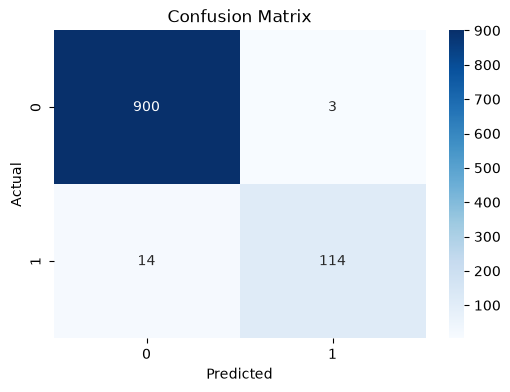

In [244]:
cm = confusion_matrix(y_test,predicted_y)


plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d',cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Created a pipeline for preventing multiple transform calls

In [245]:
spam_classifier = Pipeline([("clean",FunctionTransformer(clean_batch)),("tfidf", tfidf_vectorizer),("mnb",multi_NB)])

# Save the pipeline into joblib file

In [246]:
os.makedirs(os.path.dirname(model_path),exist_ok=True)
joblib.dump(spam_classifier,model_path)

['../models/mail_classifier.joblib']

# Loading the joblib file and predicting

In [247]:
import joblib

mail_classifier = joblib.load(model_path)

text = input("Enter the mail text: ")
if not clean(text):
    print("Invalid Input: Enter a text with some alphabets or digits")
result = mail_classifier.predict([text])[0]
result_prob = mail_classifier.predict_proba([text])

if result == 0:
    print(f"Ham with a probability of {round(result_prob[0][0] * 100,2)}%")
else:
    print(f"Spam with a probability of {round(result_prob[0][1] * 100,2)}%")

Spam with a probability of 97.98%
